# Aula 7.3 — Desafio: investigando a Random Forest

Dataset **Breast Cancer Wisconsin** (`load_breast_cancer`): 569 exames de tumores de mama, com 30 medidas das células (raio, textura, perímetro, área, concavidade...). O objetivo é prever se o tumor é **maligno** ou **benigno**.



## 01 · Carregar o dataset

In [1]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

dados = load_breast_cancer()
X = pd.DataFrame(dados.data, columns=dados.feature_names)
y = dados.target          # 0 = maligno, 1 = benigno
print("X:", X.shape)
print("Classes:", dict(zip(dados.target_names, np.bincount(y))))

X: (569, 30)
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


## 02 · Explorar as características

Olhamos as escalas das variáveis e as correlações entre elas. Árvores **não precisam de escalonamento**, porque cada divisão compara uma variável com um limite, então a diferença de escala não atrapalha.

In [2]:
print(X.iloc[:, :6].describe().round(2).T)

corr = X.corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print()
print("Pares de características com correlação > 0.9:", (pares > 0.9).sum())
print(pares.sort_values(ascending=False).head(5).round(3))

                  count    mean     std     min     25%     50%     75%  \
mean radius       569.0   14.13    3.52    6.98   11.70   13.37   15.78   
mean texture      569.0   19.29    4.30    9.71   16.17   18.84   21.80   
mean perimeter    569.0   91.97   24.30   43.79   75.17   86.24  104.10   
mean area         569.0  654.89  351.91  143.50  420.30  551.10  782.70   
mean smoothness   569.0    0.10    0.01    0.05    0.09    0.10    0.11   
mean compactness  569.0    0.10    0.05    0.02    0.06    0.09    0.13   

                      max  
mean radius         28.11  
mean texture        39.28  
mean perimeter     188.50  
mean area         2501.00  
mean smoothness      0.16  
mean compactness     0.35  

Pares de características com correlação > 0.9: 21
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64


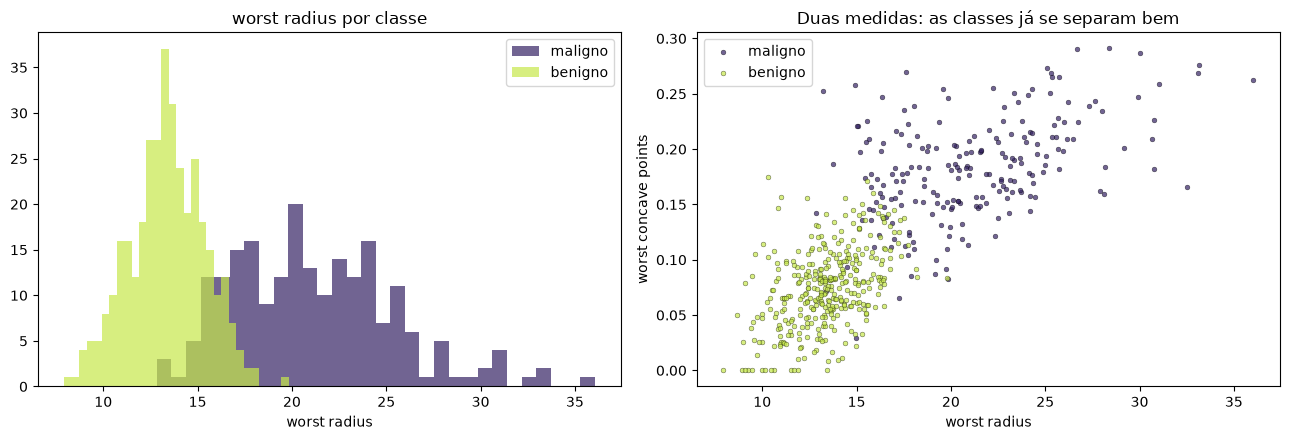

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for classe, cor, nome in [(0, "#352364", "maligno"), (1, "#C6E84A", "benigno")]:
    axes[0].hist(X.loc[y == classe, "worst radius"], bins=30, alpha=0.7, color=cor, label=nome)
    axes[1].scatter(X.loc[y == classe, "worst radius"], X.loc[y == classe, "worst concave points"],
                    s=12, alpha=0.7, color=cor, edgecolors="k", linewidths=0.3, label=nome)
axes[0].set_title("worst radius por classe"); axes[0].set_xlabel("worst radius"); axes[0].legend()
axes[1].set_title("Duas medidas: as classes já se separam bem")
axes[1].set_xlabel("worst radius"); axes[1].set_ylabel("worst concave points"); axes[1].legend()
plt.tight_layout(); plt.show()

## 03 · Separar treino e teste (75% / 25%, estratificado)

Um único split, usado por todos os modelos. O bootstrap acontece depois, **dentro** do treino.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print("Treino:", X_train.shape, np.bincount(y_train))
print("Teste: ", X_test.shape, np.bincount(y_test))

Treino: (426, 30) [159 267]
Teste:  (143, 30) [53 90]


## 04 · Treinar uma árvore de decisão (sem limite de profundidade)

In [5]:
arvore = DecisionTreeClassifier(random_state=42)
t0 = time.perf_counter()
arvore.fit(X_train, y_train)
tempo_arvore = time.perf_counter() - t0

pred_arvore = arvore.predict(X_test)
print("Profundidade:", arvore.get_depth(), "| Folhas:", arvore.get_n_leaves())
print("Acc. treino:", round(arvore.score(X_train, y_train), 4))
print("Acc. teste: ", round(accuracy_score(y_test, pred_arvore), 4))
print(confusion_matrix(y_test, pred_arvore))

Profundidade: 7 | Folhas: 18
Acc. treino: 1.0
Acc. teste:  0.9231
[[49  4]
 [ 7 83]]


## 05 · Treinar uma Random Forest (500 árvores)

Com 30 características, o padrão `max_features="sqrt"` sorteia ⌊√30⌋ = **5 candidatas por divisão**. Isso obriga as árvores a usarem variáveis diferentes e as deixa menos parecidas entre si.

In [6]:
floresta = RandomForestClassifier(n_estimators=500, oob_score=True,
                                  random_state=42, n_jobs=-1)
t0 = time.perf_counter()
floresta.fit(X_train, y_train)
tempo_floresta = time.perf_counter() - t0

pred_floresta = floresta.predict(X_test)
print("Acc. treino:", round(floresta.score(X_train, y_train), 4))
print("Acc. teste: ", round(accuracy_score(y_test, pred_floresta), 4))
print("OOB:        ", round(floresta.oob_score_, 4))
print(confusion_matrix(y_test, pred_floresta))
print("Discordâncias com a árvore:", (pred_floresta != pred_arvore).sum())

Acc. treino: 1.0
Acc. teste:  0.958
OOB:         0.9624
[[49  4]
 [ 2 88]]
Discordâncias com a árvore: 9


## 06 · Comparar quantidades de árvores

In [7]:
quantidades = [1, 5, 10, 25, 50, 100, 200, 500]
resultados_n = []
for n in quantidades:
    usa_oob = n >= 25   # com poucas árvores, algumas amostras ficam sem cobertura OOB
    rf = RandomForestClassifier(n_estimators=n, oob_score=usa_oob,
                                random_state=42, n_jobs=-1)
    t0 = time.perf_counter()
    rf.fit(X_train, y_train)
    tempo = time.perf_counter() - t0
    resultados_n.append({"n_estimators": n,
                         "acc_treino": rf.score(X_train, y_train),
                         "acc_teste": rf.score(X_test, y_test),
                         "oob": rf.oob_score_ if usa_oob else np.nan,
                         "tempo_s": tempo})
tabela_n = pd.DataFrame(resultados_n)
print(tabela_n.round(4).to_string(index=False))

 n_estimators  acc_treino  acc_teste    oob  tempo_s
            1      0.9859     0.9231    NaN   0.0209
            5      1.0000     0.9371    NaN   0.0202
           10      1.0000     0.9510    NaN   0.0294
           25      1.0000     0.9510 0.9507   0.0362
           50      1.0000     0.9510 0.9601   0.1438
          100      1.0000     0.9580 0.9624   0.1140
          200      1.0000     0.9580 0.9624   0.1932
          500      1.0000     0.9580 0.9624   0.5699


## 07 · Investigar profundidades (árvore × floresta)

In [8]:
profundidades = [1, 2, 3, 4, 6, 8, None]
resultados_d = []
for d in profundidades:
    a = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    f = RandomForestClassifier(n_estimators=500, max_depth=d, random_state=42,
                               n_jobs=-1).fit(X_train, y_train)
    for nome, m in [("Árvore", a), ("Floresta", f)]:
        resultados_d.append({"modelo": nome, "max_depth": str(d),
                             "acc_treino": m.score(X_train, y_train),
                             "acc_teste": m.score(X_test, y_test)})
tabela_d = pd.DataFrame(resultados_d)
print(tabela_d.pivot(index="max_depth", columns="modelo",
                     values=["acc_treino", "acc_teste"])
              .reindex([str(d) for d in profundidades]).round(4))

          acc_treino         acc_teste        
modelo      Floresta  Árvore  Floresta  Árvore
max_depth                                     
1             0.9319  0.9225    0.9161  0.9231
2             0.9671  0.9577    0.9510  0.9091
3             0.9836  0.9765    0.9580  0.9441
4             0.9930  0.9883    0.9580  0.9441
6             0.9977  0.9977    0.9580  0.9371
8             1.0000  1.0000    0.9580  0.9231
None          1.0000  1.0000    0.9580  0.9231


## 08 · Utilizar o OOB

O OOB avalia cada amostra de treino só com as árvores que **não** a viram (≈36,8% delas). É uma estimativa do teste que sai "de graça", sem separar dados de validação. Abaixo comparamos o OOB com o teste à medida que o número de árvores cresce.

In [9]:
t = tabela_n.dropna(subset=["oob"])
print(t[["n_estimators", "oob", "acc_teste"]].assign(diferenca=t["oob"] - t["acc_teste"]).round(4).to_string(index=False))
print()
print(f"Floresta de 500: OOB = {floresta.oob_score_:.4f} | teste = {floresta.score(X_test, y_test):.4f}")
print(f"1 erro no teste = 1/{len(y_test)} = {100/len(y_test):.2f} p.p.")

 n_estimators    oob  acc_teste  diferenca
           25 0.9507      0.951    -0.0003
           50 0.9601      0.951     0.0090
          100 0.9624      0.958     0.0044
          200 0.9624      0.958     0.0044
          500 0.9624      0.958     0.0044

Floresta de 500: OOB = 0.9624 | teste = 0.9580
1 erro no teste = 1/143 = 0.70 p.p.


## 09 · Examinar as importâncias

- **MDI** (`feature_importances_`): redução de Gini acumulada no treino; soma 1.
- **Permutação**: quanto a acurácia **no teste** cai quando embaralhamos uma coluna (10 repetições).

In [10]:
imp = pd.DataFrame({"MDI": floresta.feature_importances_}, index=X.columns)
perm = permutation_importance(floresta, X_test, y_test, n_repeats=10,
                              random_state=42, n_jobs=-1)
imp["perm_media"] = perm.importances_mean
imp["perm_desvio"] = perm.importances_std
imp = imp.sort_values("MDI", ascending=False)
print("Soma MDI:", round(imp["MDI"].sum(), 4))
print(imp.head(10).round(4))
print()
print("Top 5 por permutação:")
print(imp.sort_values("perm_media", ascending=False).head(5)[["perm_media", "perm_desvio"]].round(4))
print()
print("Características com permutação <= 0:", (imp["perm_media"] <= 0).sum(), "de", len(imp))

Soma MDI: 1.0
                         MDI  perm_media  perm_desvio
worst area            0.1350     -0.0063       0.0079
worst perimeter       0.1346     -0.0049       0.0045
worst concave points  0.1241      0.0007       0.0079
mean concave points   0.0966      0.0007       0.0049
worst radius          0.0844     -0.0056       0.0061
mean perimeter        0.0542      0.0000       0.0000
mean radius           0.0505      0.0000       0.0000
mean concavity        0.0452      0.0000       0.0000
mean area             0.0416      0.0000       0.0000
area error            0.0323      0.0000       0.0000

Top 5 por permutação:
                      perm_media  perm_desvio
worst texture             0.0042       0.0034
worst smoothness          0.0021       0.0032
worst concavity           0.0007       0.0021
worst concave points      0.0007       0.0079
mean concave points       0.0007       0.0049

Características com permutação <= 0: 25 de 30


## 10 · Comparar métricas

Aqui a classe positiva para precisão e recall é a **0 = maligno**, que é o erro que mais importa: deixar passar um tumor maligno.

In [11]:
arvore_rasa = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
floresta_rasa = RandomForestClassifier(n_estimators=500, max_depth=4, oob_score=True,
                                       random_state=42, n_jobs=-1).fit(X_train, y_train)

modelos = {"Árvore (sem limite)": arvore, "Árvore rasa (depth 4)": arvore_rasa,
           "Random Forest": floresta, "Random Forest rasa (depth 4)": floresta_rasa}
linhas = []
for nome, m in modelos.items():
    p = m.predict(X_test)
    linhas.append({"modelo": nome,
                   "treino": m.score(X_train, y_train),
                   "teste": accuracy_score(y_test, p),
                   "precisão (maligno)": precision_score(y_test, p, pos_label=0),
                   "recall (maligno)": recall_score(y_test, p, pos_label=0),
                   "F1 (maligno)": f1_score(y_test, p, pos_label=0),
                   "OOB": getattr(m, "oob_score_", np.nan),
                   "malignos não detectados": confusion_matrix(y_test, p)[0, 1]})
tabela_final = pd.DataFrame(linhas).set_index("modelo")
print(tabela_final.round(4).to_string())

t0 = time.perf_counter(); arvore.predict(X_test); prev_arvore = time.perf_counter() - t0
t0 = time.perf_counter(); floresta.predict(X_test); prev_floresta = time.perf_counter() - t0
print()
print(f"Treino:   árvore {tempo_arvore:.4f} s | floresta {tempo_floresta:.4f} s")
print(f"Previsão: árvore {prev_arvore:.4f} s | floresta {prev_floresta:.4f} s")

                              treino   teste  precisão (maligno)  recall (maligno)  F1 (maligno)     OOB  malignos não detectados
modelo                                                                                                                           
Árvore (sem limite)           1.0000  0.9231              0.8750            0.9245        0.8991     NaN                        4
Árvore rasa (depth 4)         0.9883  0.9441              0.9245            0.9245        0.9245     NaN                        4
Random Forest                 1.0000  0.9580              0.9608            0.9245        0.9423  0.9624                        4
Random Forest rasa (depth 4)  0.9930  0.9580              0.9608            0.9245        0.9423  0.9554                        4

Treino:   árvore 0.0429 s | floresta 0.6688 s
Previsão: árvore 0.0009 s | floresta 0.0531 s


## 11 · Gráficos comparativos

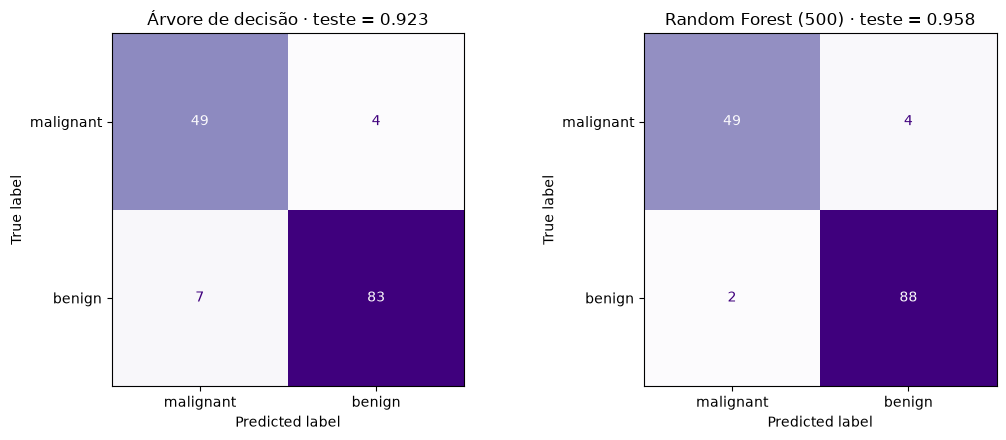

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nome, m) in zip(axes, [("Árvore de decisão", arvore), ("Random Forest (500)", floresta)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=dados.target_names,
                                          cmap="Purples", colorbar=False, ax=ax)
    ax.set_title(f"{nome} · teste = {m.score(X_test, y_test):.3f}")
plt.tight_layout(); plt.show()

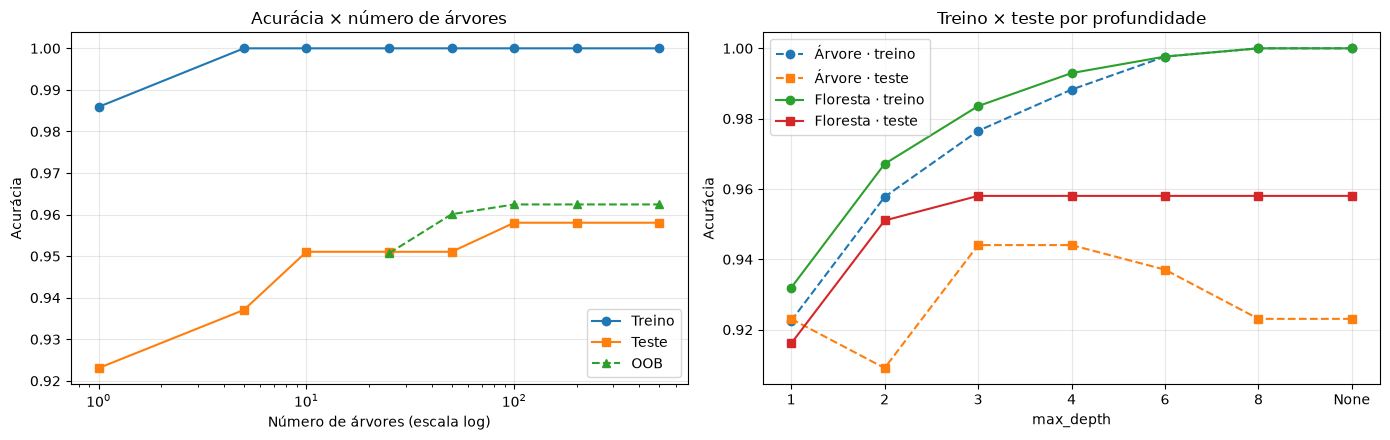

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.plot(tabela_n["n_estimators"], tabela_n["acc_treino"], "o-", label="Treino")
ax.plot(tabela_n["n_estimators"], tabela_n["acc_teste"], "s-", label="Teste")
ax.plot(tabela_n["n_estimators"], tabela_n["oob"], "^--", label="OOB")
ax.set_xscale("log"); ax.set_xlabel("Número de árvores (escala log)"); ax.set_ylabel("Acurácia")
ax.set_title("Acurácia × número de árvores"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
for nome, estilo in [("Árvore", "--"), ("Floresta", "-")]:
    t = tabela_d[tabela_d["modelo"] == nome]
    ax.plot(t["max_depth"], t["acc_treino"], "o" + estilo, label=f"{nome} · treino")
    ax.plot(t["max_depth"], t["acc_teste"], "s" + estilo, label=f"{nome} · teste")
ax.set_xlabel("max_depth"); ax.set_ylabel("Acurácia"); ax.set_title("Treino × teste por profundidade")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

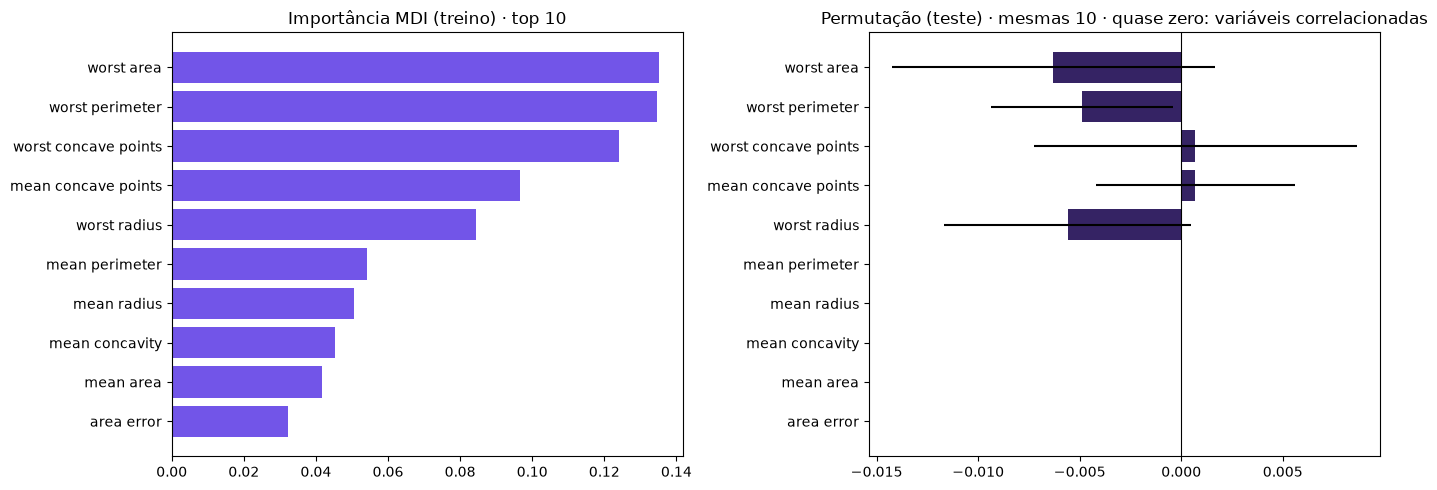

In [14]:
top = imp.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top.index, top["MDI"], color="#7255E8")
axes[0].set_title("Importância MDI (treino) · top 10")
axes[1].barh(top.index, top["perm_media"], xerr=top["perm_desvio"], color="#352364")
axes[1].axvline(0, color="k", linewidth=0.8)
axes[1].set_title("Permutação (teste) · mesmas 10 · quase zero: variáveis correlacionadas")
plt.tight_layout(); plt.show()

## 12 · Interpretação dos resultados

**1. A floresta ganhou da árvore?** Sim. A árvore sem limite acertou **100% do treino e 92,3% do teste**: decorou o treino. A Random Forest de 500 árvores também acertou 100% do treino, mas chegou a **95,8% no teste**. São **5 acertos a mais em 143** (cada ponto vale 0,70 p.p.). As duas erram os mesmos 4 malignos. O ganho veio dos falsos alarmes: a árvore chamou 7 tumores benignos de malignos e a floresta, só 2.

**2. Quantidade de árvores.** Uma árvore sozinha teve 92,3%, 10 árvores já chegaram a 95,1% e **100 árvores a 95,8%**. Daí até 500, o teste não mudou e o tempo de treino subiu de 0,18 s para 0,89 s. É o ganho decrescente que o slide mostra: mais árvores deixam a média mais estável, mas depois de um ponto não melhoram o resultado.

**3. Profundidade.** A árvore piora conforme fica mais profunda: o melhor teste foi com **max_depth = 3 ou 4 (94,4%)**, e sem limite ela cai para 92,3% (overfitting). A floresta chega a 95,8% com max_depth = 3 e **não piora mais**, nem sem limite. É a média de 500 árvores diferentes cancelando a variância de cada uma.

**4. OOB.** O OOB da floresta de 500 deu **96,2%** contra **95,8%** no teste, uma diferença de 0,44 p.p., menor que um único acerto no teste. Ou seja, o OOB estimou bem o desempenho **sem gastar dados de validação**. Com 25 árvores ou mais, OOB e teste ficaram sempre a menos de 1 p.p. um do outro.

**5. Importâncias.** Pelo **MDI**, as mais importantes foram `worst area`, `worst perimeter`, `worst concave points`, `mean concave points` e `worst radius`, todas medidas de **tamanho e concavidade** do tumor. Já a **permutação** deu quase zero para tudo (25 das 30 com valor ≤ 0). Isso **não** quer dizer que nada importa. Este dataset tem **21 pares de variáveis com correlação acima de 0,9** (raio, perímetro e área medem praticamente a mesma coisa). Quando embaralhamos `worst area`, a floresta continua usando `worst perimeter` e `worst radius`, que carregam a mesma informação, e a acurácia nem se mexe. É o defeito da permutação apontado no slide ("sofre com correlação"). E as duas medidas mostram **o uso pelo modelo, não causalidade**.

**6. Métricas.** Em precisão para maligno, a floresta teve 96,1% e a árvore, 87,5%. Em F1, 0,942 contra 0,899. O **recall foi igual (92,5%)**: os quatro modelos deixaram passar os mesmos 4 tumores malignos. Para uso médico, esse é o próximo ponto a atacar, por exemplo baixando o limiar de decisão de 0,5 no `predict_proba` para priorizar o recall.

**7. Custo.** A floresta levou **0,88 s para treinar e 0,085 s para prever**, contra 0,027 s e 0,001 s da árvore: cerca de 30 vezes mais lenta no treino. Neste dataset pequeno é irrelevante, mas a floresta também perde a interpretabilidade: uma árvore de profundidade 4 dá para desenhar e explicar, 500 árvores não.

**Conclusão:** a Random Forest generalizou melhor que a árvore (95,8% × 92,3%) e ficou estável com qualquer profundidade, enquanto a árvore sozinha precisou de poda para não decorar o treino. Para este problema, uma floresta de **100 árvores** já entrega o mesmo resultado que a de 500, com um quinto do custo.